# Part 1C: Critical Analysis

**Paper:** Montori et al., "A Metadata-Assisted Cascading Ensemble Classification Framework for Automatic Annotation of Open IoT Data", IEEE Internet of Things Journal, 10(15), 2023

In this notebook, I test whether the reproduced conclusions hold beyond the paper's single split and ideal conditions. It contains eight experiments (Exp14 to Exp21) covering repeated splits, leakage-aware splits, calibration, metadata corruption, information-domain ablation, implementation ambiguities, label noise and honest exhaustive search. Every method is kept in every table, not just the best one


## Setup

In [1]:
# load the shared critical-analysis and plotting functions
from pathlib import Path
import sys
import warnings
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.linalg import LinAlgWarning
from sklearn.exceptions import ConvergenceWarning

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from mace.config import CRITICAL_ANALYSIS_CONFIG
from mace.criticalAnalysis import (
    prepareBaselines, runCalibrationEvidence, runDomainAblation, runLabelNoise, runLeakageAwareSplits,
    runMetadataRobustness, runPaperCodeSensitivity, runRepeatedSplits, runTrainingOnlyBruteForce
)
from mace.plotting import applyPlotStyle, plotRobustness, plotSeedSpread, saveFigure

# logistic regression is fitted on unscaled features to match the released code (see notebook 2, Exp5)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
# the smallest ThingSpeak class has 4 streams so it cannot appear in all five CV folds (see notebook 1, Exp2)
warnings.filterwarnings("ignore", message="The least populated class")
# ridge on unscaled features is ill-conditioned (see notebook 1, Exp4)
warnings.filterwarnings("ignore", category=LinAlgWarning)

applyPlotStyle()

## Exp14: Repeated-Split Robustness

Seven stratified seeds measure how strongly every valid method depends on one favourable partition. The output reports mean standard deviation minimum and maximum for each method

Accuracy                     F1             \
                                     mean  std   min   max  mean  std   min   
Dataset          Method                                                       
Swissex          Best standalone     78.4  3.6  74.0  84.6  75.2  5.1  68.2   
                 MACE PF             77.5  4.5  71.2  84.6  74.1  5.4  68.2   
                 MACE SoF            77.3  3.7  73.1  82.7  73.7  4.4  68.2   
                 MACE Top-k          77.9  4.1  73.1  84.6  74.5  5.3  68.2   
                 Soft voting         77.9  2.6  75.0  81.7  74.0  4.1  68.0   
ThingSpeakEU     Best standalone     74.3  1.2  72.5  76.0  73.4  2.8  69.9   
                 MACE PF             81.2  1.6  78.8  83.5  64.2  6.7  51.0   
                 MACE SoF            86.8  2.9  80.4  88.5  75.9  8.9  56.2   
                 MACE Top-k          82.6  1.1  81.2  84.3  67.2  2.6  62.6   
                 Soft voting         78.3  1.4  76.5  80.1  56.8  3.8  51.6   
UrbanObservatory Best standalone     89.4  1.4  87.2  91.2  84.9  2.0  81.8   
                 MACE PF             89.2  1.5  86.9  91.2  84.7  2.3  81.1   
                 MACE SoF            89.2  1.9  85.6  91.2  84.7  2.3  81.3   
                 MACE Top-k          89.2  1.5  87.2  91.2  84.6  2.2  81.8   
                 Soft voting         89.7  1.2  87.5  90.9  85.9  1.9  83.1   

                                        
                                   max  
Dataset          Method                 
Swissex          Best standalone  83.2  
                 MACE PF          83.2  
                 MACE SoF         80.0  
                 MACE Top-k       83.2  
                 Soft voting      79.3  
ThingSpeakEU     Best standalone  77.8  
                 MACE PF          70.1  
                 MACE SoF         82.3  
                 MACE Top-k       70.5  
                 Soft voting      62.5  
UrbanObservatory Best standalone  88.2  
                 MACE PF          88.2  
                 MACE SoF         88.2  
                 MACE Top-k       88.2  
                 Soft voting      88.5

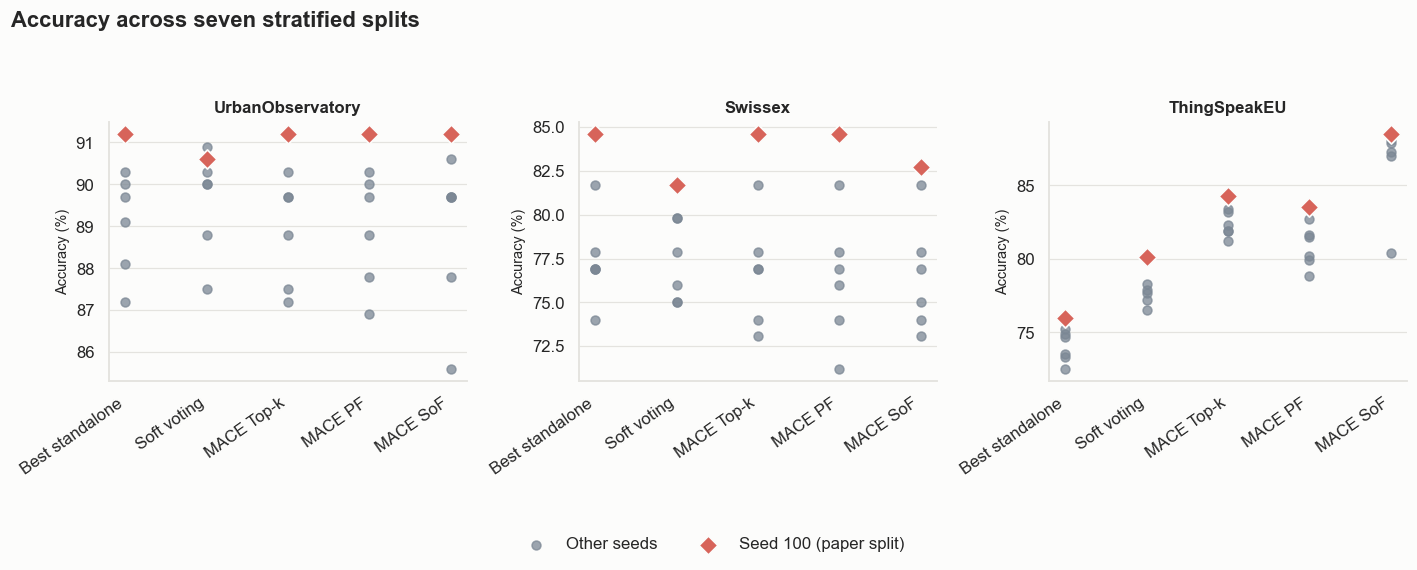

In [2]:
# retain every method for every repeated split and summarise accuracy and macro F1
repeatedResults, repeatedSummary = runRepeatedSplits(CRITICAL_ANALYSIS_CONFIG['randomSeeds'])
display(repeatedSummary[['Accuracy', 'F1']].round(1))
figure = plotSeedSpread(repeatedResults, 'Accuracy', 'Accuracy across seven stratified splits')
saveFigure(figure, 'repeatedSplitAccuracy')
plt.show()

### Findings

- Seed 100, the split used in the paper and in notebook 2, gives the highest accuracy of the seven seeds for every MACE strategy on every dataset. The paper's headline numbers sit at the top of the range rather than the middle
- Averaged over seven splits, MACE SoF scores 89.2 ± 1.9 on UrbObs, 77.3 ± 3.7 on Swissex and 86.8 ± 2.9 on ThingSpeak, which is 2.0, 5.4 and 1.7 points below the seed-100 values
- On UrbObs and Swissex, MACE is no better than the best standalone classifier on average (UrbObs 89.2 vs 89.4.. Swissex 77.3 to 77.9 vs 78.4) and soft voting is level with or ahead of it (89.7 on UrbObs)
- On ThingSpeak the gain is real and stable. MACE SoF beats the best standalone classifier by 12.5 points on average (86.8 vs 74.3) and soft voting by 8.5 points (78.3) and all three MACE strategies beat both baselines on every one of the seven seeds
- ThingSpeak SoF is also the least stable strategy. Six of the seven seeds fall between 87.0% and 88.5%, but seed 202 drops to 80.4% and macro F1 is 75.9 ± 8.9 (56.2 to 82.3). Rare classes drive this variation

## Exp15: Duplicate-Aware and Channel-Grouped Evaluation

The faithful row split is compared with a stratified exact-duplicate grouping. ThingSpeak also receives a stratified channel-group split so records from one channel cannot appear in both partitions

In [3]:
# compare row duplicate-group and channel-group protocols
leakageTable = runLeakageAwareSplits()
display(leakageTable.pivot_table(
    index=['Dataset', 'Method'], columns='Experiment', values=['Accuracy', 'F1'], aggfunc='first', sort=False
))

Accuracy                   \
Experiment                       Split_stratified Split_groupAware   
Dataset          Method                                              
UrbanObservatory Best standalone             91.2             91.2   
                 Soft voting                 90.6             90.7   
                 MACE Top-k                  91.2             91.0   
                 MACE PF                     91.2             90.7   
                 MACE SoF                    91.2             92.4   
Swissex          Best standalone             84.6             68.7   
                 Soft voting                 81.7             71.3   
                 MACE Top-k                  84.6             68.7   
                 MACE PF                     84.6             68.7   
                 MACE SoF                    82.7             68.7   
ThingSpeakEU     Best standalone             76.0             73.7   
                 Soft voting                 80.1             77.5   
                 MACE Top-k                  84.3             83.0   
                 MACE PF                     83.5             81.6   
                 MACE SoF                    88.5             90.4   

                                                                  F1  \
Experiment                       Split_channelAware Split_stratified   
Dataset          Method                                                
UrbanObservatory Best standalone                NaN             88.2   
                 Soft voting                    NaN             88.5   
                 MACE Top-k                     NaN             88.2   
                 MACE PF                        NaN             88.2   
                 MACE SoF                       NaN             88.2   
Swissex          Best standalone                NaN             83.2   
                 Soft voting                    NaN             77.8   
                 MACE Top-k                     NaN             83.2   
                 MACE PF                        NaN             83.2   
                 MACE SoF                       NaN             80.0   
ThingSpeakEU     Best standalone               72.5             71.9   
                 Soft voting                   77.3             58.8   
                 MACE Top-k                    81.2             67.6   
                 MACE PF                       80.3             64.8   
                 MACE SoF                      86.7             79.4   

                                                                      
Experiment                       Split_groupAware Split_channelAware  
Dataset          Method                                               
UrbanObservatory Best standalone             87.0                NaN  
                 Soft voting                 86.8                NaN  
                 MACE Top-k                  87.4                NaN  
                 MACE PF                     87.0                NaN  
                 MACE SoF                    88.3                NaN  
Swissex          Best standalone             66.3                NaN  
                 Soft voting                 67.2                NaN  
                 MACE Top-k                  66.3                NaN  
                 MACE PF                     66.3                NaN  
                 MACE SoF                    66.3                NaN  
ThingSpeakEU     Best standalone             76.6               70.8  
                 Soft voting                 53.5               59.5  
                 MACE Top-k                  74.0               63.7  
                 MACE PF                     62.4               62.7  
                 MACE SoF                    84.2               80.6

### Findings

- Removing exact-duplicate leakage barely changes UrbObs (MACE 90.7% to 92.4% against 91.2%)
- Swissex drops sharply under the duplicate-aware split: the best standalone classifier and every MACE strategy fall to 68.7%, below the worst of the seven random splits in Exp14 (74.0%). Only 4 duplicate groups crossed the original split so part of this drop comes from the different partition itself.. a single grouped split cannot fully separate the two effects
- On ThingSpeak the MACE advantage survives both grouped splits. With every channel kept entirely on one side, MACE SoF still reaches 86.7% against 72.5% for the best standalone classifier and 77.3% for soft voting, only 1.8 points below the faithful split
- The duplicate-aware split even raises ThingSpeak SoF to 90.4% (F1 84.2) so leakage does not drive the paper's ThingSpeak result

## Exp16: Class Balance and Probability Quality

Accuracy is read beside macro metrics and the multiclass Brier score. This prevents majority-class success from being mistaken for reliable multiclass behaviour

In [4]:
# compare discrimination balance and probability calibration
# prepare the seed-100 baselines once here and reuse them in Exp17 and Exp19
baselinePrepared = prepareBaselines()
calibrationTable = runCalibrationEvidence(baselinePrepared)
display(calibrationTable[['Dataset', 'Method', 'Accuracy', 'F1', 'AUC', 'LogLoss', 'BrierScore']])

,Dataset,Method,Accuracy,F1,AUC,LogLoss,BrierScore
0,UrbanObservatory,Soft voting,90.6,88.5,99.3,0.4850,0.196772
1,UrbanObservatory,MACE Top-k,91.2,88.2,98.9,0.3730,0.153171
2,UrbanObservatory,MACE PF,91.2,88.2,98.9,0.3730,0.153171
3,UrbanObservatory,MACE SoF,91.2,88.2,98.7,0.3775,0.154875
4,Swissex,Soft voting,81.7,77.8,97.1,0.7325,0.314039
5,Swissex,MACE Top-k,84.6,83.2,97.2,0.6284,0.274789
6,Swissex,MACE PF,84.6,83.2,97.2,0.6284,0.274789
7,Swissex,MACE SoF,82.7,80.0,92.0,3.4301,0.289089
8,ThingSpeakEU,Soft voting,80.1,58.8,97.1,0.7486,0.322198
9,ThingSpeakEU,MACE Top-k,84.3,67.6,92.9,1.8769,0.252971


### Findings

- Soft voting has the best ranking quality on every dataset: AUC 99.3, 97.1 and 97.1 against 98.7, 92.0 and 94.2 for MACE SoF
- MACE has better Brier scores than soft voting on all three datasets (for example 0.200 vs 0.322 on ThingSpeak) but much worse log loss on Swissex (3.43 vs 0.73) and ThingSpeak (2.03 vs 0.75). Classes removed by the filter get a score of zero so any stream whose true class is filtered out receives the maximum log-loss penalty
- The paper reports no probability-based metric. MACE outputs a class rather than a calibrated probability and its scores here follow my assumption that surviving classes keep the final classifier's scores so they should not be treated as calibrated probabilities

## Exp17: ThingSpeak Metadata Robustness

Only ThingSpeak test names are corrupted. The model order and SoF value come directly from the reproduced training procedure instead of a hand-written configuration

,Dataset,Mode,CorruptionRate,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy,WeightedF1,LogLoss
0,ThingSpeakEU,missing,0.00,88.5,84.5,77.4,79.4,94.2,77.4,88.2,2.0252
1,ThingSpeakEU,missing,0.10,82.1,82.8,70.8,74.6,90.0,70.8,83.0,4.7135
2,ThingSpeakEU,missing,0.25,68.8,81.6,59.9,67.0,82.1,59.9,72.6,9.7329
3,ThingSpeakEU,missing,0.50,52.7,75.6,41.1,49.6,70.6,41.1,58.6,16.1061
4,ThingSpeakEU,missing,0.75,32.5,60.0,17.7,21.8,58.2,17.7,35.3,23.8787
5,ThingSpeakEU,missing,1.00,12.6,0.6,4.8,1.1,50.0,4.8,2.8,31.5170
6,ThingSpeakEU,delete,0.00,88.5,84.5,77.4,79.4,94.2,77.4,88.2,2.0252
7,ThingSpeakEU,delete,0.10,88.4,83.8,75.9,78.3,94.3,75.9,88.0,1.9089
8,ThingSpeakEU,delete,0.25,88.4,84.3,76.8,78.8,94.5,76.8,87.9,1.9864
9,ThingSpeakEU,delete,0.50,87.6,81.4,77.2,78.6,94.4,77.2,87.3,1.9908


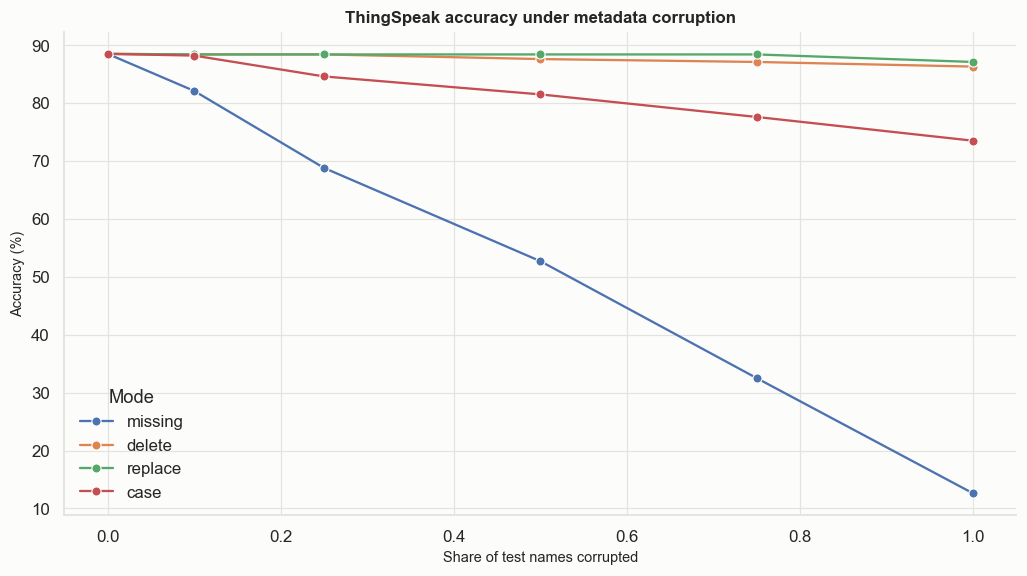

In [5]:
# measure deployment-time sensitivity to missing or changed names
metadataTable = runMetadataRobustness(
    CRITICAL_ANALYSIS_CONFIG['metadataCorruptionRates'], baselinePrepared=baselinePrepared
)
display(metadataTable)
figure = plotRobustness(
    metadataTable, "CorruptionRate", "Accuracy", "Mode", "ThingSpeak accuracy under metadata corruption",
    xLabel="Share of test names corrupted", yLabel="Accuracy (%)",
)
saveFigure(figure, 'metadataRobustness')
plt.show()

### Findings

- Small typos barely matter: deleting or replacing one character in every test name costs only 2.2 and 1.4 points (86.3% and 87.1% against 88.5%)
- Letter case matters because DDL-NLP is case-sensitive, as in the authors' code. Swapping the case of every name drops accuracy to 73.5% (-15.0), below RF alone (76.0%)
- Missing names are the main weakness. With 10% of names missing accuracy falls to 82.1%, with 25% it falls to 68.8% (already below RF alone) and with every name missing it collapses to 12.6%
- 12.6% is exactly the share of class 0 in the test set (80 of 637), which indicates that MACE predicts one class for every stream once all names are empty and RF's numerical evidence is never used. MACE has no fallback when its front classifier's information domain is absent, a practical limitation for open IoT data where metadata is often incomplete

## Exp18: Information-Domain Ablation

Every available domain subset is selected and tuned inside training data. This isolates the value of raw series statistical summaries and stream-name metadata

In [6]:
# retune every information-domain subset before test evaluation
ablationTable = runDomainAblation()
display(ablationTable)

,Dataset,Domains,Order,Sigma,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy,WeightedF1,LogLoss
0,UrbanObservatory,series,1NN-ED,-0.6,80.0,77.3,69.1,68.5,96.8,69.1,77.8,1.4372
1,UrbanObservatory,bos,SVM > RF,-0.6,91.2,89.3,88.3,88.2,98.9,88.3,91.3,0.3789
2,UrbanObservatory,series + bos,1NN-ED > RF,-0.6,91.2,89.3,88.3,88.2,98.7,88.3,91.3,0.3775
3,Swissex,series,1NN-ED,-0.6,58.7,57.7,56.3,55.3,90.7,56.3,59.9,1.4275
4,Swissex,bos,SVM > RF,-0.4,82.7,80.2,80.7,80.2,95.0,80.7,82.2,1.2779
5,Swissex,series + bos,1NN-ED > RF,0.4,82.7,79.8,81.5,80.0,92.0,81.5,81.9,3.4301
6,ThingSpeakEU,series,1NN-ED,-0.6,70.6,41.2,48.4,43.2,89.6,48.4,69.7,1.5347
7,ThingSpeakEU,bos,RF,-0.6,76.0,51.3,54.5,51.9,91.6,54.5,74.0,1.0731
8,ThingSpeakEU,metadata,DDL-NLP,-0.6,73.2,75.1,70.9,71.9,95.7,70.9,72.9,1.1627
9,ThingSpeakEU,series + bos,1NN-ED > RF,1.0,76.8,50.7,54.2,51.5,80.4,54.2,74.7,4.2979


### Findings

- On ThingSpeak, combining stream names with BOS features gives 88.5%, 12.5 points above the best single domain (BOS alone, 76.0%). This combination is the entire MACE gain
- The raw-series domain (1NN-ED) adds nothing on any dataset. Series plus BOS equals BOS alone on UrbObs (91.2%) and Swissex (82.7%) and adds only 0.8 points on ThingSpeak, series plus metadata selects DDL-NLP alone and adding the series to BOS plus metadata leaves 88.5% unchanged
- This supports the paper's position that MACE is designed for multi-domain data and shows that its single-domain results in Tables I and II come from RF alone

## Exp19: Paper-to-Code Sensitivity Analysis

PF floor versus ceiling full cascade versus early exit inverse-square versus inverse distance restricted versus unrestricted edit distance and constant-moment policies are changed one at a time

In [7]:
# retain every method under each documented ambiguity
sensitivityTable = runPaperCodeSensitivity(baselinePrepared)
sensitivityAccuracy = sensitivityTable.pivot_table(
    index='Experiment', columns=['Dataset', 'Method'], values='Accuracy', aggfunc='first', sort=False
)
display(sensitivityAccuracy)

# show each variant's accuracy change from the released-code baseline
display(sensitivityAccuracy.sub(sensitivityAccuracy.loc['LegacyBaseline'], axis=1).round(1))

Dataset               UrbanObservatory                                 \
Method                 Best standalone Soft voting MACE Top-k MACE PF   
Experiment                                                              
LegacyBaseline                    91.2        90.6       91.2    91.2   
PFCeiling                         91.2        90.6       91.2    91.2   
EarlyExit                         91.2        90.6       91.2    91.2   
TrainingMedianMoments             90.0        89.7       90.0    90.0   
DDLPowerOne                        NaN         NaN        NaN     NaN   
DDLUnrestricted                    NaN         NaN        NaN     NaN   

Dataset                                Swissex                                 \
Method                MACE SoF Best standalone Soft voting MACE Top-k MACE PF   
Experiment                                                                      
LegacyBaseline            91.2            84.6        81.7       84.6    84.6   
PFCeiling                 91.2            84.6        81.7       84.6    84.6   
EarlyExit                 91.2            84.6        81.7       84.6    84.6   
TrainingMedianMoments     90.0            84.6        82.7       84.6    84.6   
DDLPowerOne                NaN             NaN         NaN        NaN     NaN   
DDLUnrestricted            NaN             NaN         NaN        NaN     NaN   

Dataset                           ThingSpeakEU                                 \
Method                MACE SoF Best standalone Soft voting MACE Top-k MACE PF   
Experiment                                                                      
LegacyBaseline            82.7            76.0        80.1       84.3    83.5   
PFCeiling                 82.7            76.0        80.1       84.3    84.3   
EarlyExit                 82.7            76.0        80.1       84.3    83.5   
TrainingMedianMoments     82.7            75.5        80.1       84.1    83.4   
DDLPowerOne                NaN            76.0        79.9       84.3    83.5   
DDLUnrestricted            NaN            76.0        80.1       84.5    83.7   

Dataset                         
Method                MACE SoF  
Experiment                      
LegacyBaseline            88.5  
PFCeiling                 88.5  
EarlyExit                 88.5  
TrainingMedianMoments     88.5  
DDLPowerOne               88.9  
DDLUnrestricted           88.5

Dataset               UrbanObservatory                                 \
Method                 Best standalone Soft voting MACE Top-k MACE PF   
Experiment                                                              
LegacyBaseline                     0.0         0.0        0.0     0.0   
PFCeiling                          0.0         0.0        0.0     0.0   
EarlyExit                          0.0         0.0        0.0     0.0   
TrainingMedianMoments             -1.2        -0.9       -1.2    -1.2   
DDLPowerOne                        NaN         NaN        NaN     NaN   
DDLUnrestricted                    NaN         NaN        NaN     NaN   

Dataset                                Swissex                                 \
Method                MACE SoF Best standalone Soft voting MACE Top-k MACE PF   
Experiment                                                                      
LegacyBaseline             0.0             0.0         0.0        0.0     0.0   
PFCeiling                  0.0             0.0         0.0        0.0     0.0   
EarlyExit                  0.0             0.0         0.0        0.0     0.0   
TrainingMedianMoments     -1.2             0.0         1.0        0.0     0.0   
DDLPowerOne                NaN             NaN         NaN        NaN     NaN   
DDLUnrestricted            NaN             NaN         NaN        NaN     NaN   

Dataset                           ThingSpeakEU                                 \
Method                MACE SoF Best standalone Soft voting MACE Top-k MACE PF   
Experiment                                                                      
LegacyBaseline             0.0             0.0         0.0        0.0     0.0   
PFCeiling                  0.0             0.0         0.0        0.0     0.8   
EarlyExit                  0.0             0.0         0.0        0.0     0.0   
TrainingMedianMoments      0.0            -0.5         0.0       -0.2    -0.1   
DDLPowerOne                NaN             0.0        -0.2        0.0     0.0   
DDLUnrestricted            NaN             0.0         0.0        0.2     0.2   

Dataset                         
Method                MACE SoF  
Experiment                      
LegacyBaseline             0.0  
PFCeiling                  0.0  
EarlyExit                  0.0  
TrainingMedianMoments      0.0  
DDLPowerOne                0.4  
DDLUnrestricted            0.0

### Findings

- PFCeiling (PF keeps the ceiling rather than the floor of q times the remaining classes, as the paper describes): the largest MACE change is 0.8 points, for MACE PF on ThingSpeak (83.5% to 84.3%)
- EarlyExit (the cascade stops as soon as one class remains, as the paper describes, instead of running every stage as the released code does): no MACE accuracy changes on any dataset (largest change 0.0 points)
- DDLPowerOne (DDL-NLP scores classes by inverse distance, as the paper describes, instead of the released code's inverse-squared distance.. ThingSpeak only): the largest MACE change is 0.4 points, for MACE SoF on ThingSpeak (88.5% to 88.9%)
- DDLUnrestricted (unrestricted instead of restricted Damerau-Levenshtein distance.. ThingSpeak only): the largest MACE change is 0.2 points, for MACE Top-k on ThingSpeak (84.3% to 84.5%), with the same change for MACE PF (83.5% to 83.7%)
- TrainingMedianMoments (undefined skewness and kurtosis are filled with training medians instead of 0): the largest MACE change is 1.2 points, for MACE Top-k on UrbObs (91.2% to 90.0%), with the same drop for MACE PF and MACE SoF on UrbObs
- Replacing the zero-moment rule with training medians changes ThingSpeak by at most 0.5 points (best standalone 76.0% to 75.5%.. MACE SoF unchanged at 88.5%)
- Only TrainingMedianMoments changes a MACE accuracy by more than 1 point: all three MACE strategies on UrbObs fall by 1.2 points (91.2% to 90.0%). Every other documented ambiguity changes MACE accuracy by at most 0.8 points
- The UrbObs drop under TrainingMedianMoments also hits the best standalone classifier by the same 1.2 points (4 of 320 test streams) so it is a change in RF's features rather than in the cascade. The variants that follow the paper's text instead of the code (PFCeiling, EarlyExit, DDLPowerOne) move MACE by at most 0.8 points so the text-versus-code differences do not explain any gap to the paper

## Exp20: Training-Label Noise Analysis

Noise is applied only to training labels. Each altered training set receives fresh classifier ordering and SoF tuning before the untouched test set is evaluated

,Dataset,NoiseRate,Order,Sigma,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy,WeightedF1,LogLoss
0,UrbanObservatory,0.00,1NN-ED > RF,-0.6,91.2,89.3,88.3,88.2,98.7,88.3,91.3,0.3775
1,UrbanObservatory,0.05,1NN-ED > RF,0.0,91.2,89.9,87.4,87.8,98.9,87.4,91.2,0.6143
2,UrbanObservatory,0.10,SVM > GBoost > RF,-0.4,86.2,84.4,77.6,79.4,90.2,77.6,86.1,2.0313
3,UrbanObservatory,0.20,1NN-ED > SVM > GBoost > RF,-0.6,86.2,79.0,78.6,78.5,93.9,78.6,85.8,1.1826
4,Swissex,0.00,1NN-ED > RF,0.4,82.7,79.8,81.5,80.0,92.0,81.5,81.9,3.4301
5,Swissex,0.05,1NN-ED > GBoost > RF,-0.6,80.8,78.9,80.8,78.9,95.5,80.8,79.9,1.0345
6,Swissex,0.10,SVM > RF,-0.6,77.9,76.4,73.7,72.5,93.4,73.7,77.2,1.4305
7,Swissex,0.20,1NN-ED > SVM > GBoost > RF,-0.6,70.2,69.9,68.6,67.9,91.7,68.6,70.4,2.7410
8,ThingSpeakEU,0.00,DDL-NLP > RF,0.2,88.5,84.5,77.4,79.4,94.2,77.4,88.2,2.0252
9,ThingSpeakEU,0.05,GBoost > DDL-NLP > RF,-0.2,79.9,56.7,62.2,58.0,80.9,62.2,79.2,6.3767


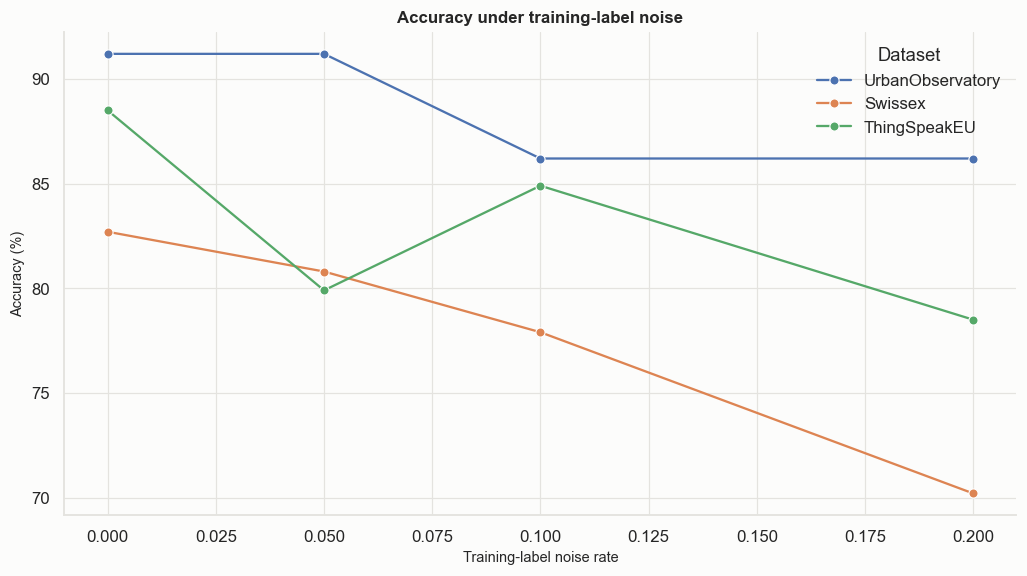

In [8]:
# retune after each controlled training-label corruption level
noiseTable = runLabelNoise(CRITICAL_ANALYSIS_CONFIG['labelNoiseRates'])
display(noiseTable)
figure = plotRobustness(
    noiseTable, "NoiseRate", "Accuracy", "Dataset", "Accuracy under training-label noise",
    xLabel="Training-label noise rate", yLabel="Accuracy (%)",
)
saveFigure(figure, 'labelNoise')
plt.show()

### Findings

- Label noise changes which classifiers the heuristic selects. On ThingSpeak, 5% noise switches the order to GBoost > DDL-NLP > RF and accuracy drops from 88.5% to 79.9% (macro F1 79.4 to 58.0), a larger drop than at 10% noise (84.9%), where the original order is selected again
- UrbObs is unaffected at 5% noise but loses 5.0 points at 10%, when the order switches to SVM > GBoost > RF. Swissex degrades steadily from 82.7% to 70.2% at 20%
- The non-monotonic ThingSpeak curve shows the damage comes mainly from unstable selection: a few mislabelled training streams are enough to change the top-k comparisons the heuristic relies on

## Exp21: Training-Only Exhaustive SoF Selection

The paper oracle chooses its configuration on test labels. This alternative selects the complete SoF configuration on a validation portion of training data then evaluates the untouched test set once

In [9]:
# separate valid selection evidence from the paper oracle
trainingOnlyTable = runTrainingOnlyBruteForce()
display(trainingOnlyTable)

,Dataset,SelectionProtocol,ValidForRecommendation,Order,Sigma,ConfigurationsSearched,Accuracy,Precision,Recall,F1,AUC,BalancedAccuracy,WeightedF1,LogLoss
0,UrbanObservatory,TrainingOnly_ValidationSelected,True,GBoost,-0.6,2925,88.8,88.4,84.4,84.7,98.0,84.4,88.7,0.5613
1,Swissex,TrainingOnly_ValidationSelected,True,GBoost > RF > SVM,-0.2,2925,81.7,81.9,78.5,79.0,88.8,78.5,81.3,6.2515
2,ThingSpeakEU,TrainingOnly_ValidationSelected,True,DDL-NLP > RF > GBoost,0.2,2925,87.8,79.2,74.2,75.7,89.3,74.2,87.1,3.4786


### Findings

- Choosing the exhaustive SoF configuration on a validation split of the training data, with no test labels, gives 88.8% on UrbObs, 81.7% on Swissex and 87.8% on ThingSpeak
- That is 3.7, 4.8 and 1.2 points below the paper-style oracle in notebook 2 (92.5%, 86.5% and 89.0%), which measures how optimistic the paper's brute-force row is
- The simple heuristic beats this honest exhaustive search on all three datasets (MACE SoF 91.2%, 82.7% and 88.5%). With limited training data, searching 2,925 configurations overfits the validation split so the heuristic is the better practical choice

## Summary: do the paper's claims hold?

| Paper claim | Evidence | Verdict |
|---|---|---|
| MACE beats every standalone classifier on all datasets | Identical to RF on UrbObs and Swissex (Exp11).. no gain on average over seven splits (Exp14) | Holds only on ThingSpeak |
| MACE beats soft voting, especially with multiple domains | ThingSpeak +8.5 points on average.. level or behind on UrbObs and Swissex (Exp14) | Holds for multi-domain data |
| The gain comes from combining information domains | Metadata plus BOS 88.5% vs 76.0% for the best single domain.. the series domain adds nothing (Exp18) | Confirmed |
| Heuristics are close to the brute-force optimum | The heuristic beats honest exhaustive search on all three datasets.. the paper's brute-force row is 1.2 to 4.8 points optimistic (Exp21) | Holds.. brute-force row overstated |
| Reported numbers are representative | Seed 100 is the best of seven seeds for every MACE strategy (Exp14) | Optimistic by 1.7 to 5.4 points for SoF |
| Results are not driven by leakage | Channel-grouped ThingSpeak SoF 86.7% (-1.8) (Exp15) | Holds on ThingSpeak.. Swissex needs caution |
| Robustness to metadata quality (not claimed) | 25% missing names already below RF.. all missing gives 12.6% (Exp17) | Main practical weakness |

